<a href="https://colab.research.google.com/github/asantibane-star/challenge.trading.itau/blob/main/Codigo_final.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
import numpy as np
import pandas as pd

# Base generada por Limpiador_base.ipynb a partir de la base bruta (también puede ser el enlace raw de GitHub)
RUTA = r"https://github.com/asantibane-star/challenge.trading.itau/raw/refs/heads/main/base_modelo.xlsx"

datos = pd.read_excel(RUTA, sheet_name='datos', index_col='fecha')
dias_posicion = pd.read_excel(RUTA, sheet_name='auxiliares', index_col='fecha')['dias_posicion']
datos.describe()

,1 USDCLP retorno cierre,3 USDCLP momentum 5d,5 USDCLP salto apertura,6 USDCLP rango log(H/L),7 USDCLP momentum 20d,8 DXY,11 USDCNY,13 USDJPY,14 USDMXN,17 Vol FX EM (JPM),...,57 NDF tasa impl 3M,59 Vol impl CLP 1M (dif),62 NDF pts 1M,63 NDF tasa impl 1M,64 Vol impl CLP 1M (nivel),65 Flujo derivados offshore,66 Flujo derivados local,68 Y rezagada (apertura t-1 a t),Flujos disponibles (indicador),Y
count,5324.000000,5324.000000,5324.000000,5324.000000,5324.000000,5324.000000,5324.000000,5324.000000,5324.000000,5324.000000,...,5324.000000,5324.000000,5324.000000,5324.000000,5324.000000,5324.000000,5324.000000,5324.000000,5324.000000,5322.000000
mean,0.000082,0.000499,-0.000120,0.009153,0.002332,0.000039,-0.000035,0.000078,0.000110,0.000297,...,0.000828,0.000424,-0.000276,-0.000391,12.356493,-0.923366,5.136739,0.000084,0.779865,0.000075
std,0.007555,0.017315,0.004770,0.005472,0.033400,0.004812,0.001862,0.006327,0.007702,0.344130,...,0.696376,0.526219,0.179238,1.026044,4.139844,300.458833,263.420678,0.008290,0.414377,0.008284
min,-0.073694,-0.123702,-0.050907,0.000000,-0.169901,-0.027263,-0.020322,-0.038569,-0.066527,-9.280000,...,-10.730000,-8.230000,-1.550000,-10.930000,4.930000,-1784.000000,-1948.000000,-0.059149,0.000000,-0.059149
25%,-0.004210,-0.010053,-0.002409,0.005561,-0.017679,-0.002617,-0.000644,-0.003086,-0.003975,-0.100000,...,-0.080000,-0.130000,-0.060000,-0.150000,9.540000,-129.000000,-108.000000,-0.004608,1.000000,-0.004604
50%,0.000000,0.000000,-0.000065,0.008033,0.000000,0.000000,0.000000,0.000195,-0.000326,-0.010000,...,0.000000,0.000000,0.000000,0.000000,11.750000,0.000000,0.000000,0.000000,1.000000,0.000000
75%,0.004125,0.010236,0.001883,0.011442,0.021774,0.002709,0.000518,0.003452,0.003748,0.070000,...,0.080000,0.100000,0.050000,0.130000,14.100000,127.000000,127.000000,0.004570,1.000000,0.004522
max,0.043355,0.111586,0.048067,0.056553,0.216738,0.025645,0.018334,0.055042,0.079766,7.260000,...,12.560000,9.440000,2.070000,13.200000,38.980000,2247.000000,1473.000000,0.056752,1.000000,0.056752


In [2]:
# =============================================================================
# A. Indicadores técnicos del USD/CLP (calculados con precios de todas las jornadas hábiles)
# =============================================================================
precios = pd.read_excel(RUTA, sheet_name='precios', index_col='fecha')
c, h, l = np.log(precios['cierre']), np.log(precios['maximo']), np.log(precios['minimo'])

tec = pd.DataFrame(index=precios.index)
# Reglas de medias móviles (Neely, Weller y Dittmar, 1997; Menkhoff y Taylor, 2007)
tec['ma_5_20'] = c.rolling(5).mean() - c.rolling(20).mean()          # cruce corto: tendencia de semanas
tec['ma_20_50'] = c.rolling(20).mean() - c.rolling(50).mean()        # cruce medio
tec['dist_ma50'] = c - c.rolling(50).mean()                          # distancia del precio a su media de 50 días
tec['dist_ma200'] = c - c.rolling(200).mean()                        # distancia a la media de 200 días
# MACD (12, 26, 9): diferencia entre medias exponenciales y su señal
macd = c.ewm(span=12, adjust=False).mean() - c.ewm(span=26, adjust=False).mean()
tec['macd_hist'] = macd - macd.ewm(span=9, adjust=False).mean()
# Canal de Donchian de 20 días: posición del cierre entre el máximo y el mínimo del período (0 = mínimo, 1 = máximo)
tec['donchian_20'] = (c - l.rolling(20).min()) / (h.rolling(20).max() - l.rolling(20).min())
# RSI de 14 días (suavizado de Wilder)
cambio = c.diff()
alzas = cambio.clip(lower=0).ewm(alpha=1 / 14, adjust=False).mean()
bajas = (-cambio.clip(upper=0)).ewm(alpha=1 / 14, adjust=False).mean()
tec['rsi_14'] = 100 - 100 / (1 + alzas / bajas)
# Bandas de Bollinger (20 días, 2 desviaciones): %B
media20, desv20 = c.rolling(20).mean(), c.rolling(20).std()
tec['bollinger_pctb'] = (c - (media20 - 2 * desv20)) / (4 * desv20)
# Volatilidad realizada de 20 días (régimen de riesgo)
tec['vol_realizada_20'] = cambio.rolling(20).std() * np.sqrt(252)
# Precios del USD/CLP en logaritmo (conocidos al cierre de t, sin fuga)
tec['log_apertura'] = np.log(precios['apertura'])
tec['log_maximo'] = h
tec['log_cierre'] = c
tec['log_minimo'] = l
tec = tec.reindex(datos.index)          # se alinean con las filas de la base (todo usa solo datos hasta t)
print('Indicadores técnicos:', list(tec.columns))

Indicadores técnicos: ['ma_5_20', 'ma_20_50', 'dist_ma50', 'dist_ma200', 'macd_hist', 'donchian_20', 'rsi_14', 'bollinger_pctb', 'vol_realizada_20', 'log_apertura', 'log_maximo', 'log_cierre', 'log_minimo']


In [5]:
# =============================================================================
# B. Volatilidad esperada GARCH(1,1) con errores t y VENTANA MÓVIL de 5 años
# =============================================================================
!pip install arch -q

from arch import arch_model

VENTANA_GARCH = 1260    # ventana móvil óptima (5 años hábiles) para olvidar regímenes antiguos
REESTIMA = 21           # reestimación mensual de parámetros (21 jornadas hábiles)
INICIO_ECON = 504       # 2 años de historia mínima antes del primer pronóstico
BUFFER_FILTRO = 252     # 1 año de burn-in al filtrar la varianza condicional

r100 = datos['68 Y rezagada (apertura t-1 a t)'] * 100     # retorno de apertura a apertura en %
vol_garch = pd.Series(np.nan, index=r100.index)
n_obs = len(r100)

for i in range(INICIO_ECON, n_obs, REESTIMA):
    # 1. Estimación de parámetros solo con las últimas VENTANA_GARCH observaciones
    ini_est = max(0, i - VENTANA_GARCH)
    p = arch_model(r100.iloc[ini_est:i], mean='Constant', vol='GARCH', p=1, q=1, dist='t').fit(disp='off').params

    # 2. Actualización diaria del estado con datos observados hasta t (usando buffer móvil reciente)
    fin = min(i + REESTIMA, n_obs)
    ini_filtro = max(0, i - BUFFER_FILTRO)
    tramo = r100.iloc[ini_filtro:fin]

    sigma = arch_model(tramo, mean='Constant', vol='GARCH', p=1, q=1, dist='t').fix(p).conditional_volatility
    s2_siguiente = p['omega'] + p['alpha[1]'] * (tramo - p['mu'])**2 + p['beta[1]'] * sigma**2   # varianza de t+1 con info hasta t
    vol_t2 = np.sqrt(p['omega'] + (p['alpha[1]'] + p['beta[1]']) * s2_siguiente)                 # volatilidad esperada de t+2

    vol_garch.iloc[i:fin] = vol_t2.iloc[i - ini_filtro : fin - ini_filtro]

econ = pd.DataFrame({'GARCH vol t+2': vol_garch})
print('Volatilidad GARCH (ventana móvil 1260d) desde', econ.dropna().index.min().date(), '| último valor (%):', round(vol_garch.iloc[-1], 3))

Volatilidad GARCH (ventana móvil 1260d) desde 2006-01-20 | último valor (%): 0.914


In [6]:
from sklearn.preprocessing import StandardScaler,PolynomialFeatures
from sklearn.linear_model import Ridge
from sklearn import metrics
from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report

In [7]:
# =============================================================================
# C. Variables, objetivo y fechas
# =============================================================================
INICIO_TRAIN = '2015-01-01'    # el modelo no usa datos anteriores a esta fecha
INICIO_VAL = '2023-01-01'      # validación: aquí se eligen ventana, C y umbrales
FIN_VAL = '2024-06-30'
INICIO_TEST = '2024-07-01'     # prueba: solo se mira al final
PURGA = 2                      # la Y de un día se conoce dos aperturas después
COSTO = 0.0003                 # supuesto: 3 pb por cada unidad que cambia la exposición
BASE_DIAS = 360                # supuesto: carry en base 360

# Variables: las de la base + técnicos (bloque A) + GARCH (bloque B)
todas = datos.drop(columns='Y').join(tec).join(econ)
x_hoy = todas.iloc[[-1]]                                   # último cierre: sirve para la señal de mañana

ok = datos['Y'].notna() & todas.notna().all(axis=1)        # días con Y conocida y variables completas
X = todas[ok]
y = (datos.loc[ok, 'Y'] > 0).astype(int)                   # 1 = el dólar sube entre la apertura de t+1 y la de t+2
ret = datos.loc[ok, 'Y']                                   # retorno logarítmico de ese mismo tramo
carry = datos.loc[ok, '52 Carry CLP-USD (nivel)'] / 100 * dias_posicion[X.index] / BASE_DIAS

print('Validación:', len(X.loc[INICIO_VAL:FIN_VAL]), 'días | Prueba:', len(X.loc[INICIO_TEST:]), 'días | Variables:', X.shape[1])

Validación: 372 días | Prueba: 580 días | Variables: 53


In [8]:
# =============================================================================
# D. Modelo: regresión Ridge del retorno con ventana móvil
# =============================================================================

REENTRENO = 21    # el modelo se vuelve a estimar cada 21 días hábiles

VARIABLES = ['1 USDCLP retorno cierre', '3 USDCLP momentum 5d', '5 USDCLP salto apertura', '7 USDCLP momentum 20d',
             '8 DXY', '14 USDMXN', '18 USDPEN', '19 USDCOP', '21 Cobre LME', '28 MSCI EM', '34 VIX (nivel)',
             '35 UST 2Y', '52 Carry CLP-USD (nivel)', '59 Vol impl CLP 1M (dif)', '65 Flujo derivados offshore',
             '68 Y rezagada (apertura t-1 a t)', 'dist_ma50', 'GARCH vol t+2']

def entrenar(hasta, ventana, alpha):
    """Estima la regresión con las `ventana` filas anteriores a la fila `hasta`."""
    desde = max(X.index.searchsorted(INICIO_TRAIN), hasta - ventana)
    x_train, r_train = X[VARIABLES].iloc[desde:hasta], ret.iloc[desde:hasta]
    escala = StandardScaler().fit(x_train)
    modelo = Ridge(alpha=alpha).fit(escala.transform(x_train), r_train)
    return escala, modelo

def predecir(desde, hasta, ventana, alpha):
    """Retorno esperado día a día, usando solo información pasada."""
    fechas = X.loc[desde:hasta].index
    mu = pd.Series(index=fechas, dtype=float)
    for i, fecha in enumerate(fechas):
        if i % REENTRENO == 0:                                      # al comienzo de cada mes se reentrena
            fila = X.index.get_loc(fecha)
            escala, modelo = entrenar(fila - PURGA, ventana, alpha)  # se dejan fuera las 2 filas cuya Y aún no se conoce
        mu[fecha] = modelo.predict(escala.transform(X.loc[[fecha], VARIABLES]))[0]
    return mu

# Grilla: se elige la combinación con mayor AUC en validación (qué tan bien ordena días de alza y de baja)
ret_val = ret[INICIO_VAL:FIN_VAL]
grilla = []
for ventana in [504, 756, 1008, 1260]:                 # 2, 3, 4 y 5 años
    for alpha in [10, 100, 1000, 10000]:               # alpha grande = más regularización
        mu = predecir(INICIO_VAL, FIN_VAL, ventana, alpha)
        grilla.append({'ventana': ventana, 'alpha': alpha,
                       'AUC': metrics.roc_auc_score(y[INICIO_VAL:FIN_VAL], mu)})
grilla = pd.DataFrame(grilla).sort_values('AUC', ascending=False)
display(grilla.head(5).round(4))

VENTANA, ALPHA = int(grilla.iloc[0]['ventana']), grilla.iloc[0]['alpha']
print(f'Elegido: ventana = {VENTANA} días, alpha = {ALPHA}')

# Retorno esperado del modelo elegido, desde el inicio de la validación hasta el último día con Y conocida
mu = predecir(INICIO_VAL, None, VENTANA, ALPHA)

,ventana,alpha,AUC
5,756,100,0.5571
4,756,10,0.5551
6,756,1000,0.5511
8,1008,10,0.5487
9,1008,100,0.5479


Elegido: ventana = 756 días, alpha = 100.0


In [9]:
# =============================================================================
# E. Política de inversión: cuándo operar, con qué exposición y cada cuántos días decidir
# =============================================================================
def pnl(pos):
    """Resultado diario por unidad de nocional: spot + carry - costos."""
    giro = pos.diff().abs().fillna(pos.abs())        # cuánto cambia la exposición (el primer día parte desde 0)
    spot = pos * np.expm1(ret[pos.index])            # ganancia por el movimiento del dólar
    carry_pagado = -pos * carry[pos.index]           # comprado en dólar paga el carry; vendido lo recibe
    costos = -COSTO * giro
    return pd.DataFrame({'pos': pos, 'spot': spot, 'carry': carry_pagado, 'costos': costos,
                         'neto': spot + carry_pagado + costos})

def sharpe(r):
    return np.sqrt(252) * r.mean() / r.std() if r.std() > 0 else 0

def posicion(mu, carry_dia, k1, k3, cada):
    """±1 si la ganancia esperada neta de carry supera k1 veces el costo de entrar y salir; ±3 si supera k3 veces.
    Solo se decide cada `cada` días; entre medio se mantiene la posición."""
    borde = np.expm1(mu) - carry_dia                  # lo que se espera ganar por unidad comprada en dólar
    costo = 2 * COSTO                                 # entrar y salir
    reglas = [borde > k3 * costo, borde > k1 * costo, borde < -k3 * costo, borde < -k1 * costo]
    pos = pd.Series(np.select(reglas, [3, 1, -3, -1], default=0), index=mu.index)
    return pos.where(np.arange(len(pos)) % cada == 0).ffill().astype(int)

# Se elige la política con mayor Sharpe neto en validación (gana más por unidad de riesgo)
mu_val = mu[INICIO_VAL:FIN_VAL]
politicas = []
for k1 in [0.5, 1, 2]:              # exigencia para exposición 1
    for k3 in [2, 3, 5]:            # exigencia para exposición 3
        for cada in [1, 2, 5]:      # decidir todos los días, día por medio o una vez por semana
            r = pnl(posicion(mu_val, carry[mu_val.index], k1, k3, cada))
            acumulado = r['neto'].cumsum()
            politicas.append({'k1': k1, 'k3': k3, 'cada': cada, 'Sharpe neto': sharpe(r['neto']),
                              'P/L neto %': 100 * r['neto'].sum(), 'Máx. caída %': 100 * (acumulado - acumulado.cummax()).min()})
politicas = pd.DataFrame(politicas).sort_values('Sharpe neto', ascending=False)
display(politicas.head(5).round(3))

K1, K3, CADA = politicas.iloc[0][['k1', 'k3', 'cada']]
CADA = int(CADA)
print(f'Política elegida: ±1 si se espera ganar más de {K1} veces el costo, ±3 si más de {K3} veces, decidir cada {CADA} días')

# Resultado del modelo como una sola serie, de validación a prueba
res = pnl(posicion(mu, carry[mu.index], K1, K3, CADA))

,k1,k3,cada,Sharpe neto,P/L neto %,Máx. caída %
7,0.5,5,2,1.515,40.685,-13.044
6,0.5,5,1,1.222,31.907,-11.264
3,0.5,3,1,1.192,43.304,-11.813
16,1.0,5,2,1.126,28.184,-14.424
4,0.5,3,2,1.004,38.604,-18.784


Política elegida: ±1 si se espera ganar más de 0.5 veces el costo, ±3 si más de 5.0 veces, decidir cada 2 días


,P/L spot %,P/L carry %,Costos %,P/L neto %,Sharpe neto,Máx. caída %,% días activo,% días ±3
Modelo (validación),49.245,-2.290,-6.27,40.685,1.515,-13.044,84.946,6.452
Modelo (prueba),24.391,-0.079,-7.17,17.141,0.621,-13.603,76.897,1.379
Comprar siempre (prueba),7.048,-1.586,-0.03,5.432,0.191,-17.332,100.000,0.000
No operar nunca (prueba),0.000,0.000,0.00,0.000,0.000,0.000,0.000,0.000
Exposición uno (prueba),25.837,-0.241,-14.31,11.285,0.397,-14.375,100.000,0.000


fecha       2023          2024         2025        2026      
              S1     S2     S1     S2    S1    S2    S1    S2
P/L neto % -7.67  22.83  25.53  14.99 -0.19  7.09 -4.63 -0.11

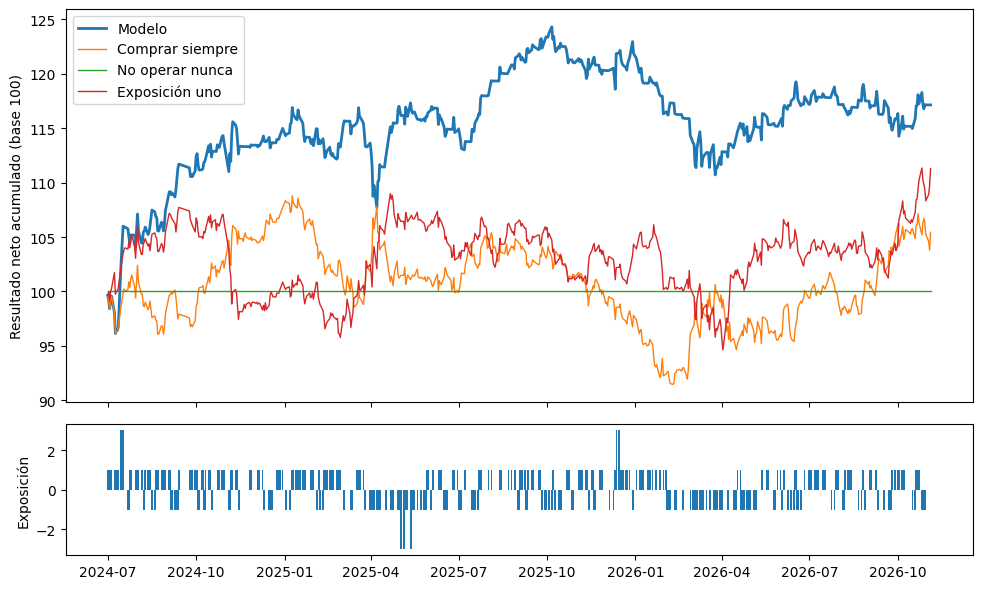

In [10]:
# =============================================================================
# F. Evaluación en prueba frente a las tres referencias de las bases
# =============================================================================
import matplotlib.pyplot as plt

def resumen(r, pred=None):
    acumulado = r['neto'].cumsum()
    fila = {'P/L spot %': 100 * r['spot'].sum(), 'P/L carry %': 100 * r['carry'].sum(),
            'Costos %': 100 * r['costos'].sum(), 'P/L neto %': 100 * r['neto'].sum(),
            'Sharpe neto': sharpe(r['neto']), 'Máx. caída %': 100 * (acumulado - acumulado.cummax()).min(),
            '% días activo': 100 * (r['pos'] != 0).mean(), '% días ±3': 100 * (r['pos'].abs() == 3).mean()}
    return fila

val, test = mu[INICIO_VAL:FIN_VAL].index, mu[INICIO_TEST:].index
referencias = {'Comprar siempre': pnl(pd.Series(1, index=test)),
               'No operar nunca': pnl(pd.Series(0, index=test)),
               'Exposición uno': pnl(pd.Series(np.where(mu[test] > 0, 1, -1), index=test))}

tabla = pd.DataFrame({'Modelo (validación)': resumen(res.loc[val], mu[val]),
                      'Modelo (prueba)': resumen(res.loc[test], mu[test])}
                     | {nombre + ' (prueba)': resumen(r) for nombre, r in referencias.items()}).T
display(tabla.round(3))

# Resultado por semestre (estabilidad)
semestre = 100 * res['neto'].groupby([res.index.year, np.where(res.index.month <= 6, 'S1', 'S2')]).sum()
display(semestre.round(2).to_frame('P/L neto %').T)

# Curva acumulada (base 100) y exposición del modelo en la prueba
fig, (arriba, abajo) = plt.subplots(2, 1, figsize=(10, 6), sharex=True, gridspec_kw={'height_ratios': [3, 1]})
arriba.plot(100 * (1 + res.loc[test, 'neto'].cumsum()), label='Modelo', lw=2)
for nombre, r in referencias.items():
    arriba.plot(100 * (1 + r['neto'].cumsum()), label=nombre, lw=1)
arriba.set_ylabel('Resultado neto acumulado (base 100)'); arriba.legend()
abajo.bar(test, res.loc[test, 'pos'], width=1.5); abajo.set_ylabel('Exposición')
plt.tight_layout(); plt.show()

In [11]:
# =============================================================================
# G. ¿Es significativo? Diebold-Mariano, bootstrap y lectura de la convicción
# =============================================================================
import statsmodels.api as sm
from scipy.stats import norm

def media_newey_west(d):
    """t de la media de d con errores Newey-West (corrige autocorrelación)."""
    est = sm.OLS(np.asarray(d), np.ones(len(d))).fit(cov_type='HAC', cov_kwds={'maxlags': 5})
    return est.tvalues[0], norm.sf(est.tvalues[0])

yt = ret[test]
perdida_modelo = -np.sign(mu[test]) * yt
perdida_comprar = -yt
t_dm, p_dm = media_newey_west(perdida_comprar - perdida_modelo)
print(f'Diebold-Mariano (modelo vs comprar siempre): t = {t_dm:.2f}, p unilateral = {p_dm:.3f}')

# Bootstrap por bloques de 10 días: ¿el P/L del modelo supera al de cada referencia por algo más que azar?
def p_bootstrap(dif, largo=10, repeticiones=2000):
    rng = np.random.default_rng(0)
    dif = dif.values
    centrada = dif - dif.mean()                                 # se simula un mundo donde la diferencia media es 0
    medias = []
    for _ in range(repeticiones):
        inicios = rng.integers(0, len(dif) - largo, size=len(dif) // largo + 1)
        muestra = np.concatenate([centrada[i:i + largo] for i in inicios])[:len(dif)]
        medias.append(muestra.mean())
    return np.mean(np.array(medias) >= dif.mean())              # qué tan seguido el azar da algo igual o mejor

for nombre, r in referencias.items():
    dif = res.loc[test, 'neto'] - r['neto']
    print(f'Modelo vs {nombre:16s}: diferencia {100 * dif.sum():6.2f}% | p bootstrap = {p_bootstrap(dif):.3f}')

# Convicción: resultado según la exposición tomada (con signo)
conv = res.loc[test].copy()
conv['acierto'] = np.where(conv['pos'] == 0, np.nan, (np.sign(conv['pos']) == np.sign(yt)).astype(float))
display(conv.groupby('pos').agg(días=('pos', 'size'), acierto=('acierto', 'mean'),
                                P_L_neto_pct=('neto', lambda s: 100 * s.sum())).round(3))

Diebold-Mariano (modelo vs comprar siempre): t = 0.86, p unilateral = 0.196
Modelo vs Comprar siempre : diferencia  11.71% | p bootstrap = 0.315
Modelo vs No operar nunca : diferencia  17.14% | p bootstrap = 0.162
Modelo vs Exposición uno  : diferencia   5.86% | p bootstrap = 0.458


,días,acierto,P_L_neto_pct
pos,,,
-3,4,0.500,-0.275
-1,194,0.531,0.771
0,134,NaN,-1.590
1,244,0.533,5.632
3,4,1.000,12.603


In [12]:
# =============================================================================
# H. Señal para la jornada siguiente
# =============================================================================
# Cada vez que se ejecuta, el modelo se reentrena con los últimos VENTANA días cuya Y ya se conoce
escala, modelo = entrenar(len(X), VENTANA, ALPHA)

# Las últimas jornadas de la base aún no tienen Y: se predicen con el modelo recién entrenado
pendientes = todas.loc[todas.index > X.index.max()]
mu_pend = pd.Series(modelo.predict(escala.transform(pendientes[VARIABLES])), index=pendientes.index)
carry_pend = pendientes['52 Carry CLP-USD (nivel)'] / 100 * 1 / BASE_DIAS     # supuesto: posición de 1 día

# Serie completa hasta hoy, para respetar el calendario de "decidir cada CADA días"
serie_mu = pd.concat([mu, mu_pend])
pos_serie = posicion(serie_mu, pd.concat([carry[mu.index], carry_pend]), K1, K3, CADA)
pos_hoy = int(pos_serie.iloc[-1])
decide_hoy = (len(serie_mu) - 1) % CADA == 0
direccion = 'COMPRA de USD' if pos_hoy > 0 else 'VENTA de USD' if pos_hoy < 0 else 'SIN POSICIÓN (en pesos)'
print(f'Datos al cierre del {pendientes.index[-1].date()} | retorno esperado = {1e4 * mu_pend.iloc[-1]:.1f} pb')
if decide_hoy:
    print(f'Día de decisión -> exposición {pos_hoy:+d} ({direccion}) en la próxima apertura')
else:
    print(f'Hoy no es día de decisión -> se mantiene la exposición vigente: {pos_hoy:+d} ({direccion})')

Datos al cierre del 2026-11-06 | retorno esperado = -20.2 pb
Hoy no es día de decisión -> se mantiene la exposición vigente: -1 (VENTA de USD)


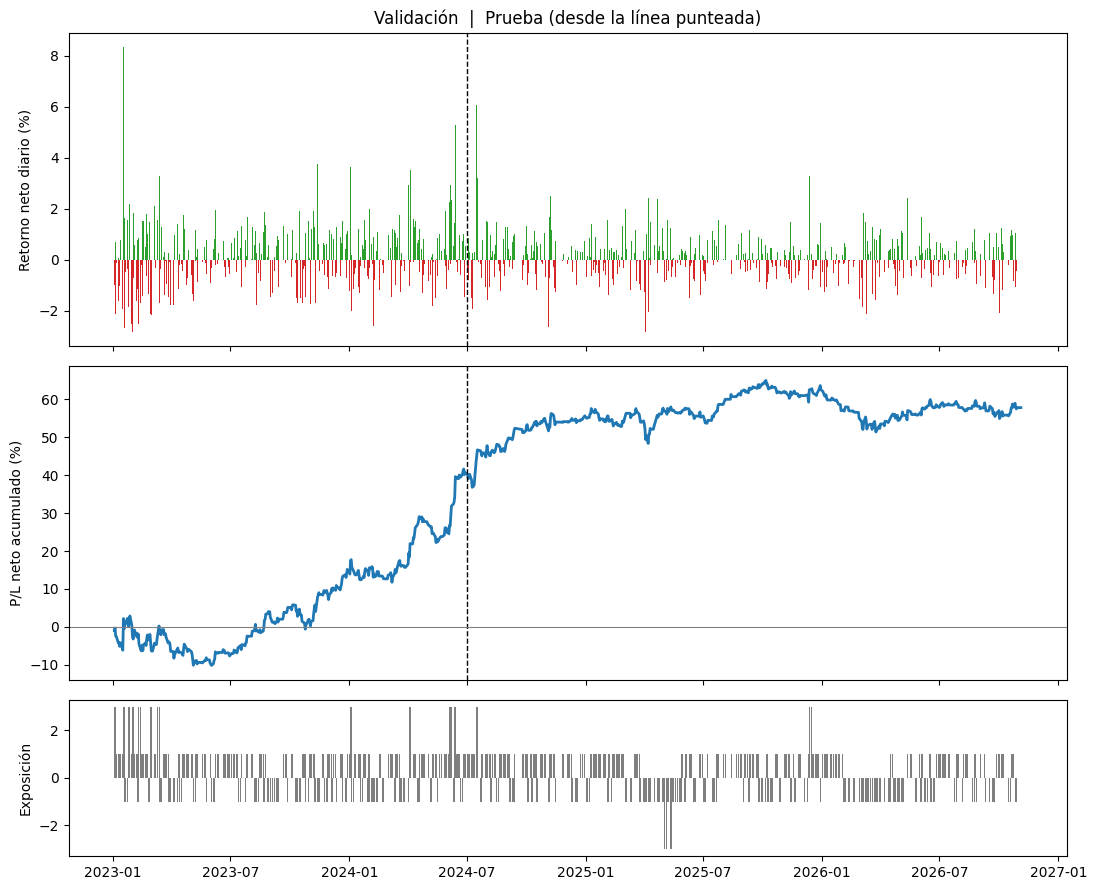

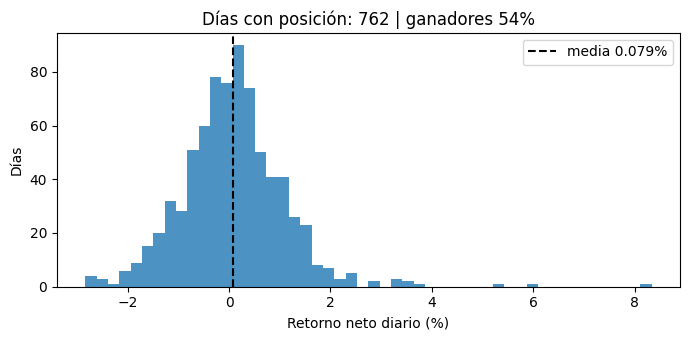

In [13]:
# =============================================================================
# Retornos diarios de la estrategia (validación y prueba)
# =============================================================================
import matplotlib.pyplot as plt

r = 100 * res['neto']                                    # retorno neto diario en % del nocional
colores = np.where(r >= 0, 'tab:green', 'tab:red')

fig, (a1, a2, a3) = plt.subplots(3, 1, figsize=(11, 9), sharex=True, gridspec_kw={'height_ratios': [2, 2, 1]})

# 1. Retorno neto de cada día
a1.bar(r.index, r, color=colores, width=1.5)
a1.axvline(pd.Timestamp(INICIO_TEST), color='black', ls='--', lw=1)
a1.set_ylabel('Retorno neto diario (%)')
a1.set_title('Validación  |  Prueba (desde la línea punteada)')

# 2. Resultado acumulado
a2.plot(r.cumsum(), color='tab:blue', lw=2)
a2.axvline(pd.Timestamp(INICIO_TEST), color='black', ls='--', lw=1)
a2.axhline(0, color='grey', lw=0.8)
a2.set_ylabel('P/L neto acumulado (%)')

# 3. Exposición vigente
a3.bar(res.index, res['pos'], width=1.5, color='tab:gray')
a3.set_ylabel('Exposición')
plt.tight_layout(); plt.show()

# Distribución de los retornos diarios en los días con posición abierta
activos = r[res['pos'] != 0]
fig, ax = plt.subplots(figsize=(7, 3.5))
ax.hist(activos, bins=50, color='tab:blue', alpha=0.8)
ax.axvline(activos.mean(), color='black', ls='--', label=f'media {activos.mean():.3f}%')
ax.set_xlabel('Retorno neto diario (%)'); ax.set_ylabel('Días'); ax.legend()
ax.set_title(f'Días con posición: {len(activos)} | ganadores {100 * (activos > 0).mean():.0f}%')
plt.tight_layout(); plt.show()